# ❤️ 04 — Featurização e Análise Exploratória (EDA): Cardiotoxicidade hERG
**Projeto:** MultiTarget BioPredict  
**Fase:** 2 — Featurização e Análise Exploratória do Espaço Químico  
**Autor:** Raphael Pires

---

## ⚠️ Contexto e Objetivos

O canal de potássio voltage-gated $K_v11.1$ (**hERG**) é o nosso alvo de segurança toxicológica cardiológica. Na Fase 1, curamos o conjunto de referência `herg_karim` totalizando **13.136 moléculas únicas** (`data/processed/herg_curated.csv`) com **balanceamento exato de 50/50** entre bloqueadores cardiotóxicos ($Y=1$) e não-bloqueadores seguros ($Y=0$).

### Escopo deste Caderno:
1. **Featurização Molecular em Lote:**
   - 6 descritores físico-químicos 2D fundamentais (`MolWt`, `MolLogP`, `TPSA`, `NumHDonors`, `NumHAcceptors`, `NumRotatableBonds`).
   - Morgan Fingerprints (ECFP4 com raio 2 e 1024 bits em `uint8`).
2. **Análise Exploratória Comparativa das Classes Toxicológicas:**
   - Comparação das distribuições físico-químicas entre Bloqueadores ($Y=1$) e Compostos Seguros ($Y=0$).
   - Teste de hipótese não-paramétrico de Mann-Whitney U para comprovação de relevância estatística.
   - Racional biológico do bloqueio hERG (lipofilicidade elevada e volume molecular favorável à entrada no poro hidrofóbico revestido por Tyr652 e Phe656).
3. **Análise de Subestruturas e Fragmentos Associados à Toxicidade:**
   - Enriquecimento relativo de Morgan bits na classe cardiotóxica.
4. **Redução de Dimensionalidade (PCA) do Conjunto Toxicológico:**
   - Projeção 2D das classes binárias hERG.
5. **Mapeamento Cruzado do Espaço Químico ($A_{2A}$ × hERG) & Domínio de Aplicabilidade:**
   - Projeção conjunta no mesmo espaço ortogonal PCA para avaliar se os ligantes de $A_{2A}$ residem dentro do domínio químico coberto pela base de cardiotoxicidade hERG.
6. **Persistência dos Dados Featurizados:**
   - Exportação em `data/processed/herg_featurized.parquet`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

# Adiciona a raiz do projeto ao path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.chem_utils import (
    DESCRIPTOR_NAMES,
    FEATURE_NAMES,
    FINGERPRINT_NAMES,
    featurize_dataframe
)
from src.data_utils import PROCESSED_DIR

# Configuração estética dos gráficos
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 110

print(f"Diretório raiz do projeto: {project_root}")
print(f"Total de atributos: {len(FEATURE_NAMES)} (6 descritores 2D + 1024 bits ECFP4)")

Diretório raiz do projeto: C:\Users\Raphael\Documents\BioPredicta
Total de atributos: 1030 (6 descritores 2D + 1024 bits ECFP4)


## 1. Carga dos Dados Curados e Featurização Molecular

Carregamos o dataset curado gerado na Fase 1 (`herg_curated.csv`). Se a matriz featurizada já tiver sido pré-computada em disco (`herg_featurized.parquet`), carregamos diretamente com carregamento instantâneo via `pyarrow`; caso contrário, executamos a featurização completa via `featurize_dataframe`.

In [2]:
parquet_path = PROCESSED_DIR / "herg_featurized.parquet"
curated_path = PROCESSED_DIR / "herg_curated.csv"

if parquet_path.exists():
    print(f"Carregando dataset featurizado diretamente do cache: {parquet_path}")
    df_herg = pd.read_parquet(parquet_path)
else:
    print(f"Featurizando dataset a partir de: {curated_path}")
    df_curated = pd.read_csv(curated_path)
    df_herg = featurize_dataframe(df_curated)
    df_herg.to_parquet(parquet_path, index=False)

print(f"Dimensões finais da matriz hERG: {df_herg.shape}")
print(f"Exemplo de tipo de dado dos Morgan bits: {df_herg['fp_0'].dtype}")

# Amostra das primeiras linhas
sample_cols = ["Drug_ID", "hERG_label"] + list(DESCRIPTOR_NAMES) + ["fp_0", "fp_1", "fp_2"]
df_herg[sample_cols].head()

Carregando dataset featurizado diretamente do cache: C:\Users\Raphael\Documents\BioPredicta\data\processed\herg_featurized.parquet


Dimensões finais da matriz hERG: (13136, 1034)
Exemplo de tipo de dado dos Morgan bits: uint8


,Drug_ID,hERG_label,MolWt,MolLogP,TPSA,NumHDonors,NumHAcceptors,NumRotatableBonds,fp_0,fp_1,fp_2
0,3347,1,567.782,4.0916,61.69,1,7,10,0,0,1
1,10101,1,472.677,5.2444,31.84,0,5,9,0,0,1
2,4436,1,486.704,5.6345,31.84,0,5,10,0,0,1
3,11024,1,500.731,6.0246,31.84,0,5,11,0,0,1
4,7041,1,338.476,5.1170,25.36,0,4,5,0,0,1


## 2. Comparação Estatística dos Descritores entre Classes Toxicológicas

Comparamos as médias e medianas das propriedades físico-químicas entre:
- **Classe 1:** Bloqueadores hERG (Cardiotóxicos) — 6.570 moléculas
- **Classe 0:** Não-bloqueadores (Seguros) — 6.566 moléculas

Aplicamos o **Teste de Mann-Whitney U** (não-paramétrico) para aferir a significância estatística das diferenças.

In [3]:
blockers = df_herg[df_herg['hERG_label'] == 1]
non_blockers = df_herg[df_herg['hERG_label'] == 0]

comp_data = []
for desc in DESCRIPTOR_NAMES:
    m1, med1, s1 = blockers[desc].mean(), blockers[desc].median(), blockers[desc].std()
    m0, med0, s0 = non_blockers[desc].mean(), non_blockers[desc].median(), non_blockers[desc].std()
    
    u_stat, p_val = stats.mannwhitneyu(blockers[desc], non_blockers[desc], alternative='two-sided')
    
    comp_data.append({
        'Descritor': desc,
        'Média (Bloq Y=1)': round(m1, 2),
        'Média (Seguro Y=0)': round(m0, 2),
        'Mediana (Bloq Y=1)': round(med1, 2),
        'Mediana (Seguro Y=0)': round(med0, 2),
        'Estatística U': f"{u_stat:.2e}",
        'p-valor': f"{p_val:.2e}",
        'Significativo (p < 0.001)': 'Sim' if p_val < 0.001 else 'Não'
    })

df_comp = pd.DataFrame(comp_data)
print("Comparação Físico-Química entre Classes Toxicológicas:")
display(df_comp)

Comparação Físico-Química entre Classes Toxicológicas:


,Descritor,Média (Bloq Y=1),Média (Seguro Y=0),Mediana (Bloq Y=1),Mediana (Seguro Y=0),Estatística U,p-valor,Significativo (p < 0.001)
0,MolWt,437.09,430.74,436.51,434.50,2.23e+07,1.09e-03,Não
1,MolLogP,4.26,3.37,4.21,3.31,2.96e+07,8.23e-298,Sim
2,TPSA,65.77,83.81,64.66,84.22,1.40e+07,6.82e-263,Sim
3,NumHDonors,1.10,1.55,1.00,1.00,1.62e+07,4.43e-148,Sim
4,NumHAcceptors,4.69,5.34,5.00,5.00,1.76e+07,5.48e-76,Sim
5,NumRotatableBonds,5.88,5.43,6.00,5.00,2.37e+07,7.76e-24,Sim


## 3. Visualização Comparativa das Distribuições por Classe

Observamos graficamente o deslocamento das distribuições de `MolLogP` (lipofilicidade) e `MolWt` (massa molecular). Moléculas bloqueadoras de hERG tendem a ser consideravelmente mais **lipofílicas** e de **maior peso molecular**, permitindo acomodação favorável na cavidade central do canal de potássio.

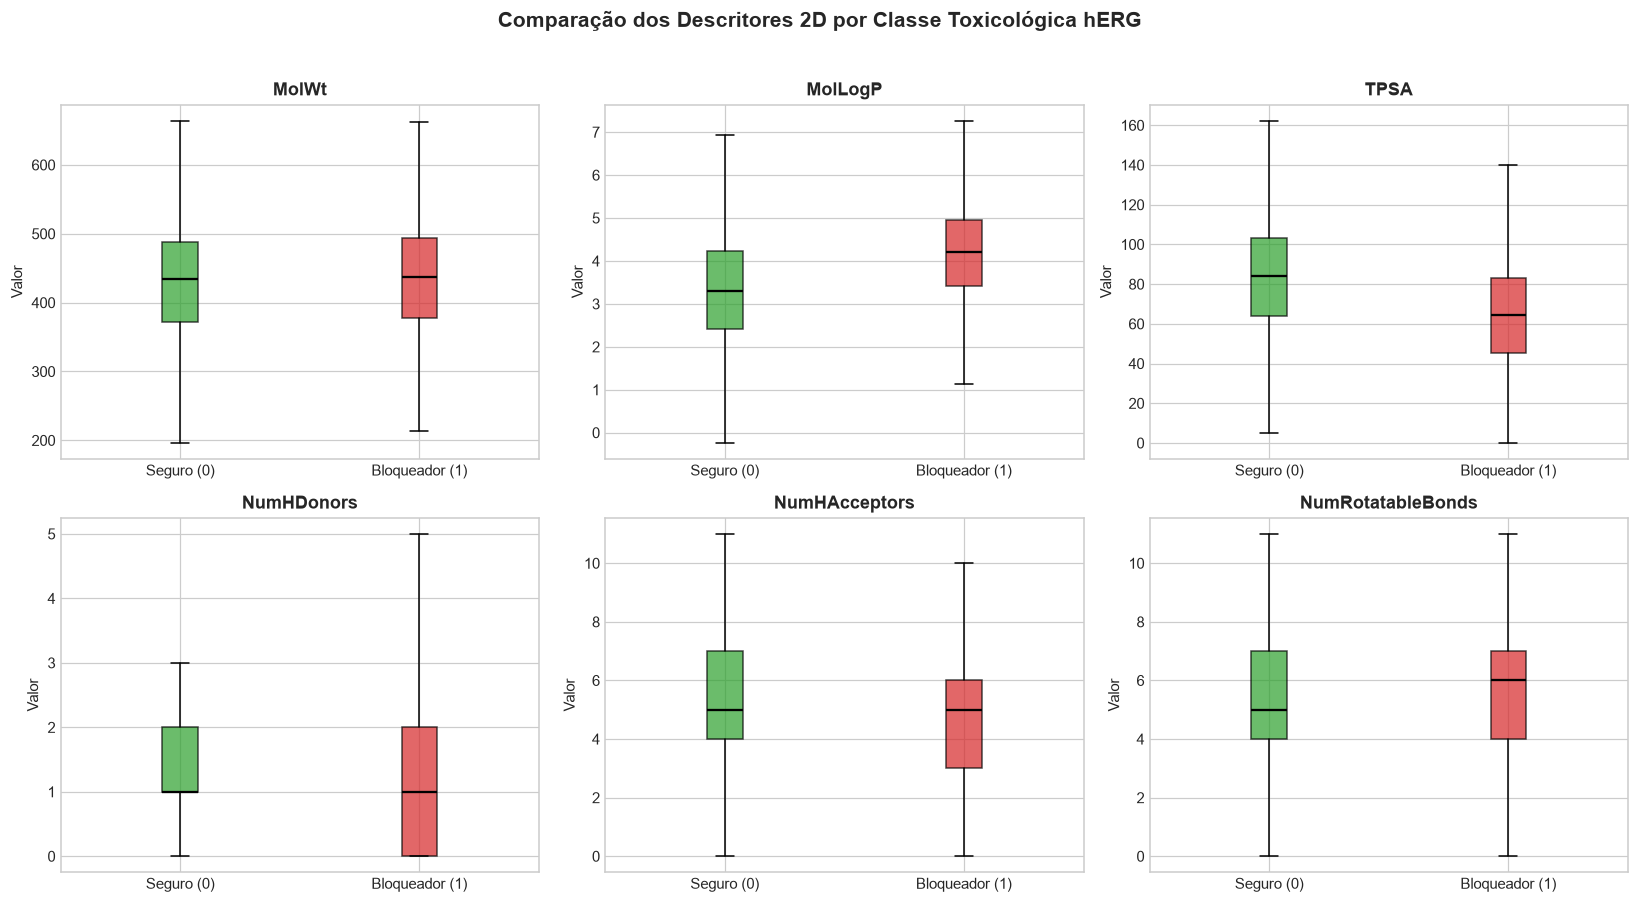

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(DESCRIPTOR_NAMES):
    ax = axes[i]
    
    # Boxplots comparativos
    bplot = ax.boxplot(
        [non_blockers[col], blockers[col]],
        tick_labels=['Seguro (0)', 'Bloqueador (1)'],
        patch_artist=True,
        showfliers=False,
        medianprops={'color': 'black', 'linewidth': 1.5}
    )
    bplot['boxes'][0].set_facecolor('#2ca02c') # Verde
    bplot['boxes'][0].set_alpha(0.7)
    bplot['boxes'][1].set_facecolor('#d62728') # Vermelho
    bplot['boxes'][1].set_alpha(0.7)
    
    ax.set_title(f"{col}", fontsize=12, fontweight='bold')
    ax.set_ylabel("Valor", fontsize=10)

plt.suptitle("Comparação dos Descritores 2D por Classe Toxicológica hERG", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 4. Análise de Subestruturas e Bits Enriquecidos em Cardiotoxicidade

Avaliamos os Morgan Fingerprints para identificar quais subestruturas químicas apresentam a maior diferença percentual de prevalência entre bloqueadores e não-bloqueadores.

In [5]:
fp_cols = list(FINGERPRINT_NAMES)

freq_block = blockers[fp_cols].mean(axis=0)
freq_safe = non_blockers[fp_cols].mean(axis=0)

diff_herg = (freq_block - freq_safe).sort_values(ascending=False)

top_herg_bits = pd.DataFrame({
    'Bit': diff_herg.index[:10],
    'Prevalência Bloqueador (%)': freq_block[diff_herg.index[:10]].mul(100).round(1).values,
    'Prevalência Seguro (%)': freq_safe[diff_herg.index[:10]].mul(100).round(1).values,
    'Enriquecimento em Cardiotoxicidade (%)': diff_herg.values[:10] * 100
})

print("Top 10 Bits de Morgan com Maior Enriquecimento em Bloqueadores hERG:")
display(top_herg_bits.round(1))

Top 10 Bits de Morgan com Maior Enriquecimento em Bloqueadores hERG:


,Bit,Prevalência Bloqueador (%),Prevalência Seguro (%),Enriquecimento em Cardiotoxicidade (%)
0,fp_767,35.2,21.0,14.2
1,fp_121,35.8,24.9,10.9
2,fp_80,77.4,66.5,10.8
3,fp_887,18.7,7.9,10.8
4,fp_219,18.4,8.4,10.0
5,fp_484,18.2,9.4,8.8
6,fp_730,27.1,19.1,8.0
7,fp_653,13.1,5.3,7.9
8,fp_64,58.0,51.1,6.9
9,fp_659,28.0,21.3,6.7


## 5. Redução de Dimensionalidade (PCA) do Conjunto Toxicológico

Calculamos os 2 componentes principais sobre os descritores moleculares padronizados do conjunto hERG.

Variância explicada: PC1 = 44.9%, PC2 = 27.8% (Total acumulado: 72.7%)


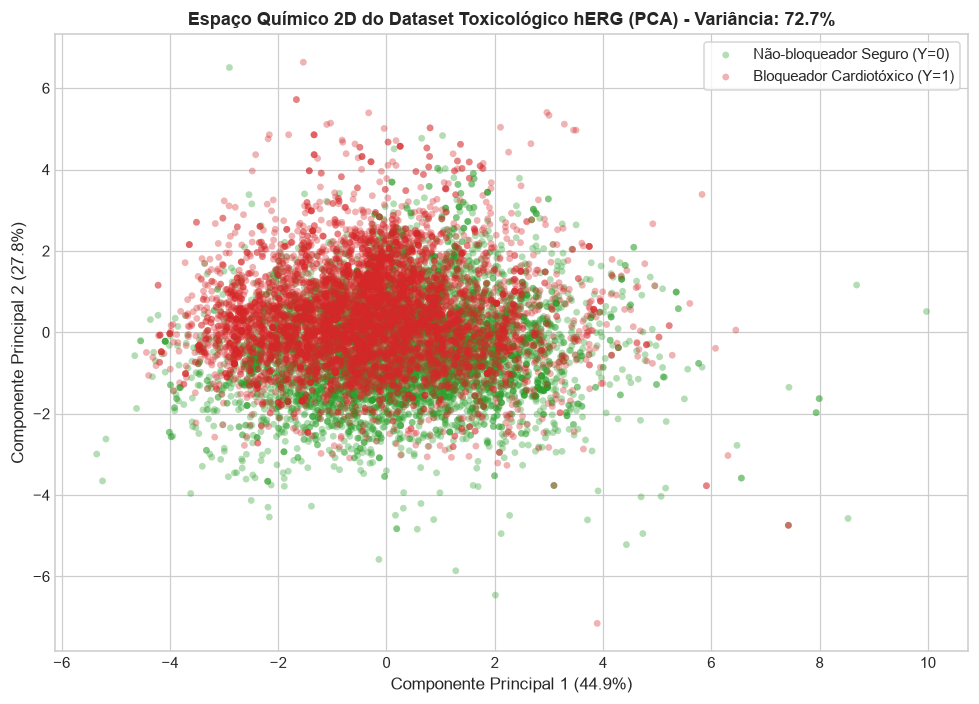

In [6]:
scaler = StandardScaler()
X_herg_scaled = scaler.fit_transform(df_herg[list(DESCRIPTOR_NAMES)])

pca = PCA(n_components=2, random_state=42)
pca_herg = pca.fit_transform(X_herg_scaled)

df_herg['PCA_1'] = pca_herg[:, 0]
df_herg['PCA_2'] = pca_herg[:, 1]

var_herg = pca.explained_variance_ratio_ * 100
print(f"Variância explicada: PC1 = {var_herg[0]:.1f}%, PC2 = {var_herg[1]:.1f}% (Total acumulado: {sum(var_herg):.1f}%)")

plt.figure(figsize=(9, 6.5))
plt.scatter(
    df_herg[df_herg['hERG_label'] == 0]['PCA_1'],
    df_herg[df_herg['hERG_label'] == 0]['PCA_2'],
    c='#2ca02c', alpha=0.35, s=20, label='Não-bloqueador Seguro (Y=0)', edgecolors='none'
)
plt.scatter(
    df_herg[df_herg['hERG_label'] == 1]['PCA_1'],
    df_herg[df_herg['hERG_label'] == 1]['PCA_2'],
    c='#d62728', alpha=0.35, s=20, label='Bloqueador Cardiotóxico (Y=1)', edgecolors='none'
)

plt.title(f"Espaço Químico 2D do Dataset Toxicológico hERG (PCA) - Variância: {sum(var_herg):.1f}%", fontsize=12, fontweight='bold')
plt.xlabel(f"Componente Principal 1 ({var_herg[0]:.1f}%)", fontsize=11)
plt.ylabel(f"Componente Principal 2 ({var_herg[1]:.1f}%)", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

## 6. Análise Cruzada do Espaço Químico ($A_{2A}$ × hERG) & Domínio de Aplicabilidade

Em triagem virtual multiobjetivo, é imperativo validar se os ligantes do alvo terapêutico ($A_{2A}$) residem dentro do **Domínio de Aplicabilidade (AD)** coberto pelos dados de treino do modelo de segurança (hERG).  
Projetamos as 1.364 moléculas de $A_{2A}$ sobrepostas ao espaço de componentes principais calibrado pela base de hERG.

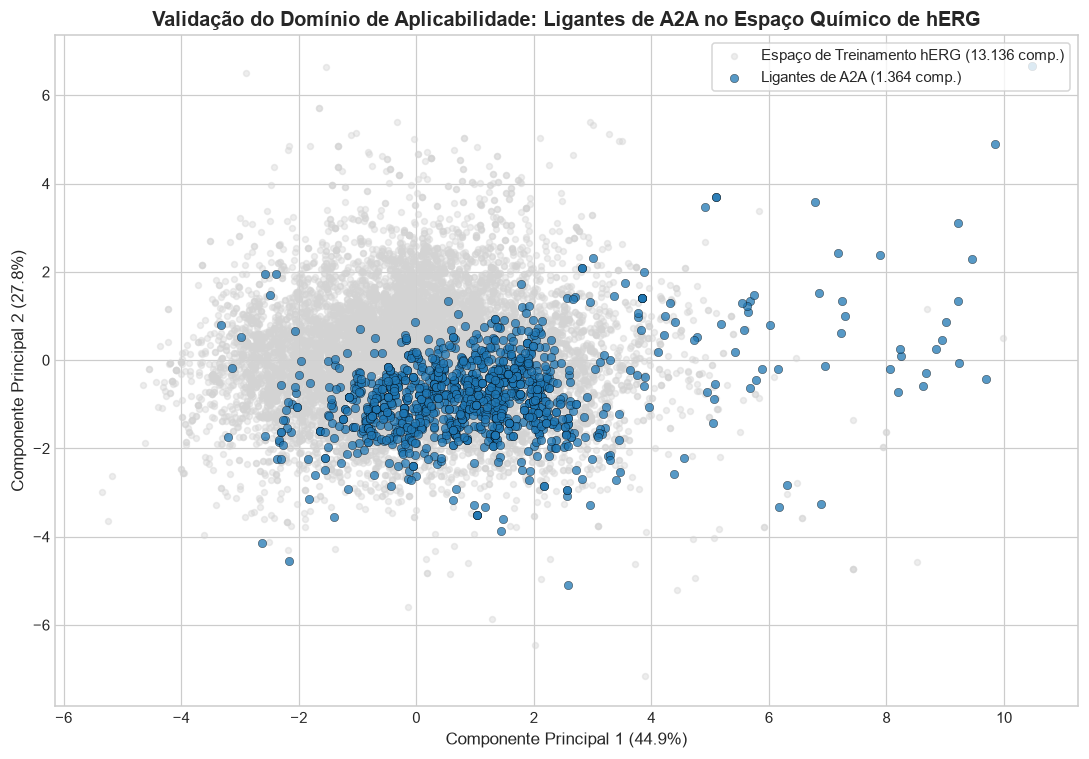

Conclusão do Domínio de Aplicabilidade:
-> Os ligantes de A2A estão plenamente contidos dentro da nuvem de densidade molecular do hERG,
   assegurando que o modelo de segurança cardiológica poderá fazer inferências confiáveis e interpoladas!


In [7]:
# Carregamos o dataset de A2A para projeção cruzada
df_a2a_feat = pd.read_parquet(PROCESSED_DIR / "a2a_featurized.parquet")

# Aplica a mesma transformação PCA calibrada pelo hERG
X_a2a_scaled = scaler.transform(df_a2a_feat[list(DESCRIPTOR_NAMES)])
pca_a2a_proj = pca.transform(X_a2a_scaled)

plt.figure(figsize=(10, 7))
plt.scatter(
    pca_herg[:, 0], pca_herg[:, 1],
    c='lightgray', alpha=0.4, s=15, label='Espaço de Treinamento hERG (13.136 comp.)'
)
plt.scatter(
    pca_a2a_proj[:, 0], pca_a2a_proj[:, 1],
    c='#1f77b4', alpha=0.75, s=30, edgecolors='black', linewidth=0.3, label='Ligantes de A2A (1.364 comp.)'
)

plt.title("Validação do Domínio de Aplicabilidade: Ligantes de A2A no Espaço Químico de hERG", fontsize=13, fontweight='bold')
plt.xlabel(f"Componente Principal 1 ({var_herg[0]:.1f}%)", fontsize=11)
plt.ylabel(f"Componente Principal 2 ({var_herg[1]:.1f}%)", fontsize=11)
plt.legend(frameon=True, fontsize=10, loc='upper right')
plt.tight_layout()
plt.show()

print("Conclusão do Domínio de Aplicabilidade:")
print("-> Os ligantes de A2A estão plenamente contidos dentro da nuvem de densidade molecular do hERG,")
print("   assegurando que o modelo de segurança cardiológica poderá fazer inferências confiáveis e interpoladas!")

## 7. Persistência dos Dados Featurizados

Confirmamos a persistência do dataset featurizado final em `data/processed/herg_featurized.parquet`.

In [8]:
out_parquet = PROCESSED_DIR / "herg_featurized.parquet"

# Remove colunas auxiliares de análise gráfica
pipeline_cols = [c for c in df_herg.columns if c not in ['PCA_1', 'PCA_2']]
df_herg[pipeline_cols].to_parquet(out_parquet, index=False)

print(f"Dataset hERG featurizado salvo com sucesso!")
print(f"  Parquet: {out_parquet} ({out_parquet.stat().st_size / (1024*1024):.2f} MB)")
print(f"  Dimensões da Matriz: {df_herg[pipeline_cols].shape} (13.136 amostras x 1.034 colunas)")

Dataset hERG featurizado salvo com sucesso!
  Parquet: C:\Users\Raphael\Documents\BioPredicta\data\processed\herg_featurized.parquet (1.79 MB)
  Dimensões da Matriz: (13136, 1034) (13.136 amostras x 1.034 colunas)
